# Signalwatch: training, validation, evaluation, and testing

**CodeAlpha Task 4 — custom rules + machine-learning IDS**

This notebook adds an interactive, executable reproduction to the existing script-based project. The originally published model was trained with Python scripts; this notebook fits a **fresh Random Forest** visibly, cell by cell.

We use the same packet decoder, feature extractor, label matching, and metric functions as the application. Experimental outputs stay under `artifacts/notebook-runs/`. The published weights, metadata, metric report, data-quality report, and dataset lock are checked before/after and are not replaced.

**Research limit:** the test captures and results have already been published. This is reproduction, not a new blind evaluation. If these results influence model changes, reserve a new untouched test set for subsequent claims. Model scores are uncalibrated, not attack probabilities.


## 1. Environment and project root

From the repository root, install `requirements-notebook.txt` in a Python 3.12 virtual environment, launch `python -m jupyterlab`, and select that environment's kernel. Choose **Restart Kernel and Run All Cells**. Running from the repository or its `notebooks/` folder is supported.

First-time preparation needs about 100 MB of public data and can take several minutes. Existing compatible caches make reproduction faster. No GPU, Docker daemon, or live capture is required for Run All.


In [1]:
from pathlib import Path
import hashlib
import json
import platform
import subprocess
import sys
import time
from datetime import datetime, timezone

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'ids_lab/features.py').is_file() and (p / 'data/sources.json').is_file()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook inside the cloned Signalwatch repository.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import joblib
import numpy as np
import pandas as pd
import sklearn
import scapy
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import ConfusionMatrixDisplay, f1_score, precision_recall_curve

from ids_lab.features import FEATURES, SCHEMA
from ids_lab.model import Model
from ids_lab.labels import LabelIndex
from ids_lab.packets import read_pcap
from ids_lab.synthetic import lab_sessions
from tools.prepare_data import extract
from tools.train_model import metrics

get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': False})

def read_json(path):
    return json.loads(Path(path).read_text())

def sha(path):
    with Path(path).open('rb') as handle:
        return hashlib.file_digest(handle, 'sha256').hexdigest()

REFERENCE_METADATA = read_json(ROOT / 'models/metadata.json')
assert platform.python_version_tuple()[:2] == ('3', '12'), 'Use Python 3.12.'
assert sklearn.__version__ == REFERENCE_METADATA['sklearn_version'], 'Install the pinned notebook requirements.'
assert REFERENCE_METADATA['schema'] == SCHEMA
assert REFERENCE_METADATA['features'] == list(FEATURES)
assert Model(ROOT / 'models').status == 'ready'
display(pd.DataFrame([{'Python': platform.python_version(), 'scikit-learn': sklearn.__version__,
                       'NumPy': np.__version__, 'feature_schema': SCHEMA, 'feature_count': len(FEATURES)}]))


,Python,scikit-learn,NumPy,feature_schema,feature_count
0,3.12.14,1.9.1,2.5.4,flow5-v1,22


## 2. Parameters and preservation checks

The defaults reproduce the published experiment. Data preparation is permitted when arrays are missing, and software tests run near the end. No cell deploys a model, starts Docker, or overwrites the published model. Change the output directory to keep separate experiments.


In [2]:
PREPARE_DATA_IF_MISSING = True
REUSE_COMPATIBLE_PROJECT_CACHE = True
RUN_SOFTWARE_TESTS = True
OUTPUT_DIR = ROOT / 'artifacts/notebook-runs/reproduction-v1'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SESSION_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')

PROTECTED_FILES = ['models/detector.joblib', 'models/metadata.json',
                   'reports/model_metrics.json', 'reports/data_quality.json', 'data/sources.lock.json']
PROTECTED_BEFORE = {name: sha(ROOT / name) for name in PROTECTED_FILES}
SOURCE = read_json(ROOT / 'data/sources.json')
LOCK = read_json(ROOT / 'data/sources.lock.json')
PUBLISHED_QUALITY = read_json(ROOT / 'reports/data_quality.json')
PUBLISHED_RESULTS = read_json(ROOT / 'reports/model_metrics.json')
print('Output directory:', OUTPUT_DIR.relative_to(ROOT))
print('Published model and reports protected by SHA-256 checks.')


Output directory: artifacts/notebook-runs/reproduction-v1
Published model and reports protected by SHA-256 checks.


## 3. Data provenance, partitions, and consistent features

IoT-23 is attributed to Garcia, Parmisano, and Erquiaga (2020), DOI [10.5281/zenodo.4743746](https://doi.org/10.5281/zenodo.4743746). Source URLs, licensing notes, and file hashes are retained in the project. Only data files are read; no malware binaries or captured packets are executed/transmitted.

Whole capture/session groups stay in one partition. Labels come from official connection intervals or declared synthetic scenario intent, not from detector outputs. Unknown/ambiguous matches are excluded.

The model uses 22 numerical statistics in five-second bidirectional windows. Raw addresses, raw port values, absolute timestamps, payload indicators, group IDs, rule results, and labels are excluded from model inputs. The same extractor handles training and runtime packets.


In [3]:
lab_plan = {group: (split, packets, labels)
            for split, group, packets, labels in lab_sessions()}
plan = [{**row, 'domain': 'public'} for row in SOURCE['captures']]
plan += [{'id': group, 'split': values[0], 'domain': 'lab'}
         for group, values in lab_plan.items()]
assert len({row['id'] for row in plan}) == len(plan), 'Duplicate group ID.'
groups = {split: {row['id'] for row in plan if row['split'] == split}
          for split in ('train', 'validation', 'test')}
assert all(not (groups[a] & groups[b]) for a, b in
           [('train', 'validation'), ('train', 'test'), ('validation', 'test')])
display(pd.DataFrame(plan)[['id', 'domain', 'split']])
display(pd.DataFrame({'feature_index': range(len(FEATURES)), 'feature': FEATURES}))


,id,domain,split
0,malware-8,public,train
1,malware-20,public,train
2,malware-21,public,validation
3,honeypot-4,public,validation
4,malware-3,public,test
5,malware-42,public,test
6,somfy-01,public,test
7,lab-100,lab,train
8,lab-101,lab,train
9,lab-102,lab,train


,feature_index,feature
0,0,duration_s
1,1,forward_packets
2,2,reverse_packets
3,3,forward_ip_bytes
4,4,reverse_ip_bytes
5,5,length_mean
6,6,length_std
7,7,length_min
8,8,length_max
9,9,iat_mean


## 4. Prepare or reuse feature arrays

Project caches are reused only when the feature/decoder/label/generator source fingerprints match the checked published source, schema/order match, and group assignments match. Notebook-owned caches include a fingerprint of code, source manifests, NumPy, and schema. Changes invalidate that cache automatically.

If preparation is needed, the notebook uses `tools.prepare_data.extract`, `LabelIndex`, `read_pcap`, and `lab_sessions` directly. It does **not** call the preparation script's main function, which would overwrite the published quality report. Newly prepared arrays/quality records go only under this experiment directory.


In [4]:
feature_files = ['ids_lab/features.py', 'ids_lab/packets.py', 'ids_lab/labels.py',
                 'ids_lab/synthetic.py', 'tools/prepare_data.py']
feature_hashes = {name: sha(ROOT / name) for name in feature_files}
checked_run = read_json(ROOT / 'reports/evidence/verification.json')
checked = checked_run['source_sha256']
reuse_project = (REUSE_COMPATIBLE_PROJECT_CACHE
                 and all(checked.get(name) == digest for name, digest in feature_hashes.items())
                 and checked_run['versions']['scapy'] == scapy.__version__
                 and checked_run['versions']['numpy'] == np.__version__
                 and PUBLISHED_QUALITY['schema'] == SCHEMA
                 and PUBLISHED_QUALITY['features'] == list(FEATURES))
fingerprint = hashlib.sha256(json.dumps({
    'code': feature_hashes, 'source': SOURCE, 'lock': LOCK,
    'schema': SCHEMA, 'features': list(FEATURES), 'numpy': np.__version__, 'scapy': scapy.__version__,
}, sort_keys=True).encode()).hexdigest()
cache_dir = OUTPUT_DIR / 'cache' / fingerprint[:16]
cache_dir.mkdir(parents=True, exist_ok=True)
published_records = {row['id']: row for row in PUBLISHED_QUALITY['captures']}
arrays, quality_rows = {}, []
fetched = False

def load_arrays(path):
    with np.load(path, allow_pickle=False) as archive:
        x, y = archive['X'], archive['y']
    assert x.ndim == 2 and x.shape[1] == len(FEATURES)
    assert y.ndim == 1 and len(x) == len(y) and np.isfinite(x).all()
    assert set(np.unique(y)).issubset({0, 1})
    return x, y

for row in plan:
    group = row['id']
    project_path = ROOT / 'data/processed' / f'{group}.npz'
    notebook_path = cache_dir / f'{group}.npz'
    prior = published_records.get(group, {})
    compatible_group = prior.get('split') == row['split'] and prior.get('domain') == row['domain']
    if reuse_project and compatible_group and project_path.exists():
        x, y = load_arrays(project_path)
        assert int(sum(y == 0)) == prior['benign'] and int(sum(y == 1)) == prior['suspicious']
        counts, origin = prior, 'checked project cache'
        data_hash = sha(project_path)
    elif notebook_path.exists() and notebook_path.with_suffix('.json').exists():
        x, y = load_arrays(notebook_path)
        counts = read_json(notebook_path.with_suffix('.json'))
        origin, data_hash = 'fingerprinted notebook cache', sha(notebook_path)
    else:
        if not PREPARE_DATA_IF_MISSING:
            raise RuntimeError(f'Missing features for {group}; enable preparation or prepare compatible data first.')
        print('Preparing', group, flush=True)
        if row['domain'] == 'public':
            paths = [ROOT / 'data/raw' / group / row['pcap'],
                     ROOT / 'data/raw' / group / 'conn.log.labeled']
            if not all(path.exists() for path in paths) and not fetched:
                from tools.fetch_data import main as fetch_public_data
                fetch_public_data()
                fetched = True
                assert sha(ROOT / 'data/sources.lock.json') == PROTECTED_BEFORE['data/sources.lock.json']
            for path in paths:
                key = f'{group}/{path.name}'
                assert sha(path) == LOCK['files'][key]['sha256'], f'Untrusted/mismatched data: {key}'
            index = LabelIndex(paths[1])
            rows, labels, counts = extract(read_pcap(paths[0]), index.match)
        else:
            _, raw_packets, labels_by_connection = lab_plan[group]
            rows, labels, counts = extract(raw_packets,
                lambda window: (labels_by_connection.get(window['connection']), 'matched'))
        x, y = np.asarray(rows, dtype=float), np.asarray(labels, dtype=np.int8)
        assert x.ndim == 2 and x.shape[1] == len(FEATURES) and np.isfinite(x).all()
        np.savez_compressed(notebook_path, X=x, y=y)
        notebook_path.with_suffix('.json').write_text(json.dumps(counts, indent=2))
        origin, data_hash = 'shared pipeline extraction', sha(notebook_path)
    arrays[group] = (x, y)
    quality_rows.append({**counts, 'id': group, 'domain': row['domain'], 'split': row['split'],
                         'benign': int(sum(y == 0)), 'suspicious': int(sum(y == 1)),
                         'samples': len(y), 'cache_origin': origin, 'array_sha256': data_hash})

quality = pd.DataFrame(quality_rows)
display(quality[['id', 'domain', 'split', 'benign', 'suspicious', 'cache_origin']])
print('Prepared/reused', len(arrays), 'independent source groups.')


,id,domain,split,benign,suspicious,cache_origin
0,malware-8,public,train,2181,8755,checked project cache
1,malware-20,public,train,3498,16574,checked project cache
2,malware-21,public,validation,4034,16558,checked project cache
3,honeypot-4,public,validation,4693,0,checked project cache
4,malware-3,public,test,5712,175568,checked project cache
5,malware-42,public,test,5396,9,checked project cache
6,somfy-01,public,test,849,0,checked project cache
7,lab-100,lab,train,51,54,checked project cache
8,lab-101,lab,train,52,82,checked project cache
9,lab-102,lab,train,50,56,checked project cache


Prepared/reused 30 independent source groups.


## 5. Audit label coverage and training balance

Excluded/unsupported cases are quality accounting, not model false positives. The training chart uses training labels only. Dataset-level class counts are shown for transparency; held-out prediction metrics are computed after threshold selection.


samples  benign  suspicious
domain split                                  
lab    test            677     305         372
       train          1378     610         768
       validation      605     250         355
public test         187534   11957      175577
       train         31008    5679       25329
       validation    25285    8727       16558

,id,matched,unmatched,unsupported_or_malformed,late_packets,capacity_dropped
0,malware-8,10936,378.0,6946.0,0,0
1,malware-20,20072,1.0,8949.0,0,0
2,malware-21,20592,0.0,9146.0,0,0
3,honeypot-4,4693,0.0,4743.0,0,0
4,malware-3,181280,14365.0,5660.0,0,0
5,malware-42,5405,79.0,1737.0,0,0
6,somfy-01,849,0.0,1745.0,0,0


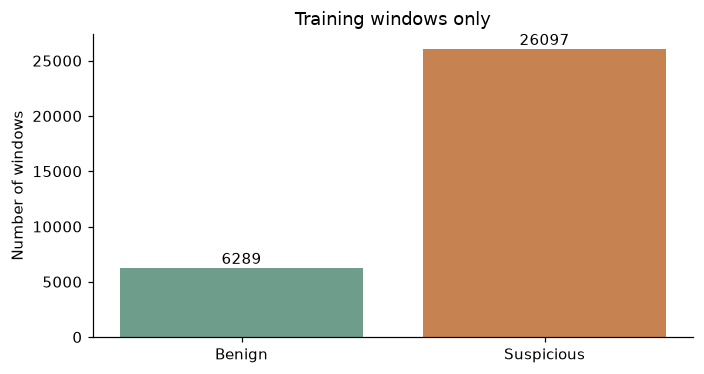

In [5]:
display(quality.groupby(['domain', 'split'])[['samples', 'benign', 'suspicious']].sum())
coverage_columns = [name for name in ['id', 'matched', 'unmatched', 'ambiguous',
                    'unsupported_or_malformed', 'late_packets', 'capacity_dropped'] if name in quality]
display(quality.loc[quality.domain == 'public', coverage_columns].fillna(0))

def partition(split, domain=None):
    selected = [row for row in plan if row['split'] == split
                and (domain is None or row['domain'] == domain)]
    return (np.concatenate([arrays[row['id']][0] for row in selected]),
            np.concatenate([arrays[row['id']][1] for row in selected]))

train_x, train_y = partition('train')
validation_x, validation_y = partition('validation')
assert len(train_x) <= 150000 and set(np.unique(train_y)) == {0, 1}
fig, ax = plt.subplots(figsize=(6.5, 3.5))
bars = ax.bar(['Benign', 'Suspicious'], [int(sum(train_y == 0)), int(sum(train_y == 1))],
              color=['#6f9d8b', '#c78252'])
ax.bar_label(bars, fmt='%d')
ax.set(title='Training windows only', ylabel='Number of windows')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'training_class_balance.png', dpi=160)
plt.show()


## 6. Fit a fresh Random Forest

Only training arrays enter `.fit`. The recipe matches the original: 200 trees, depth 10, at most 256 leaves, balanced bootstrap weights, seed 42, and two workers. No test-driven parameter search is performed here.


In [6]:
parameters = dict(n_estimators=200, max_depth=10, max_leaf_nodes=256,
                  class_weight='balanced_subsample', random_state=42, n_jobs=2)
model = RandomForestClassifier(**parameters)
started = time.perf_counter()
model.fit(train_x, train_y)
fit_seconds = time.perf_counter() - started
baseline = DummyClassifier(strategy='most_frequent').fit(train_x, train_y)
assert list(model.classes_) == [0, 1]
display(pd.DataFrame([{'training_windows': len(train_y), 'features': model.n_features_in_,
                       'fit_seconds': round(fit_seconds, 3), **parameters}]))


,training_windows,features,fit_seconds,n_estimators,max_depth,max_leaf_nodes,class_weight,random_state,n_jobs
0,32386,22,1.258,200,10,256,balanced_subsample,42,2


## 7. Choose the cutoff using validation data only

We scan 0.05–0.95 at 0.01 steps, choose maximum validation F1, and choose the higher threshold for ties. The grid is the published recipe, not a claim that it is optimal for every network. Parameters/cutoff are frozen before the next evaluation cell.


,selected_threshold,validation_f1,selection_source
0,0.95,0.998817,validation only


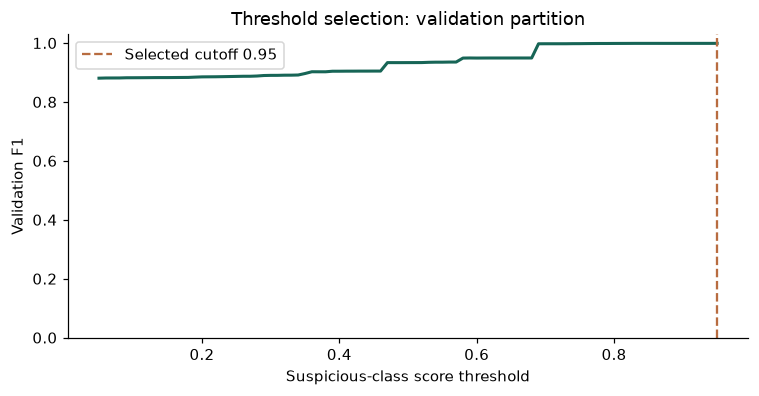

In [7]:
validation_scores = model.predict_proba(validation_x)[:, 1]
candidates = np.linspace(0.05, 0.95, 91)
validation_f1 = [f1_score(validation_y, validation_scores >= value, zero_division=0)
                 for value in candidates]
threshold = float(max(candidates,
                     key=lambda value: (f1_score(validation_y, validation_scores >= value, zero_division=0), value)))
frozen_parameters = model.get_params().copy()
display(pd.DataFrame([{'selected_threshold': threshold,
                       'validation_f1': max(validation_f1), 'selection_source': 'validation only'}]))
fig, ax = plt.subplots(figsize=(7, 3.7))
ax.plot(candidates, validation_f1, color='#176556', linewidth=2)
ax.axvline(threshold, color='#b86c40', linestyle='--', label=f'Selected cutoff {threshold:.2f}')
ax.set(xlabel='Suspicious-class score threshold', ylabel='Validation F1', ylim=(0, 1.03),
       title='Threshold selection: validation partition')
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'validation_threshold.png', dpi=160)
plt.show()


## 8. Evaluate public and lab partitions separately

Now evaluate the frozen classifier, with the same metric helper used by the script. We report precision, recall, F1, average precision, false-positive rate, class counts, and confusion matrices. Average precision is the PR-AUC summary convention used in the project.

The majority baseline is fit on training data. An imbalanced test set can give that baseline a high F1 while it flags every benign example. Do not hide false positives behind a headline score.


In [8]:
results, score_sets = {}, {}
for split in ('train', 'validation', 'test'):
    for domain in ('public', 'lab'):
        x, y = partition(split, domain)
        scores = model.predict_proba(x)[:, 1]
        majority_scores = baseline.predict_proba(x)[:, 1]
        key = f'{domain}_{split}'
        results[key] = {'random_forest': metrics(y, scores, threshold),
                        'majority_baseline': metrics(y, majority_scores, 0.5)}
        if split == 'test':
            score_sets[domain] = (y, scores)
assert model.get_params() == frozen_parameters

rows = []
for domain in ('public', 'lab'):
    for estimator in ('random_forest', 'majority_baseline'):
        values = results[f'{domain}_test'][estimator]
        cm = values['confusion_matrix']
        balanced = (cm['tp'] / max(1, cm['tp'] + cm['fn'])
                    + cm['tn'] / max(1, cm['tn'] + cm['fp'])) / 2
        rows.append({'domain': domain, 'estimator': estimator,
                     **{name: values[name] for name in ['samples', 'benign', 'suspicious', 'precision',
                        'recall', 'f1', 'pr_auc_average_precision', 'false_positive_rate']},
                     'balanced_accuracy': balanced})
evaluation = pd.DataFrame(rows)
display(evaluation.round(5))

comparison = []
for domain in ('public', 'lab'):
    for name in ('precision', 'recall', 'f1', 'false_positive_rate'):
        observed = results[f'{domain}_test']['random_forest'][name]
        published = PUBLISHED_RESULTS['results'][f'{domain}_test']['random_forest'][name]
        comparison.append({'domain': domain, 'metric': name, 'notebook': observed,
                           'published': published, 'difference': observed - published})
display(pd.DataFrame(comparison).round(8))


,domain,estimator,samples,benign,suspicious,precision,recall,f1,pr_auc_average_precision,false_positive_rate,balanced_accuracy
0,public,random_forest,187534,11957,175577,0.98875,0.92218,0.95430,0.98022,0.15414,0.88402
1,public,majority_baseline,187534,11957,175577,0.93624,1.00000,0.96707,0.93624,1.00000,0.50000
2,lab,random_forest,677,305,372,1.00000,0.99731,0.99865,1.00000,0.00000,0.99866
3,lab,majority_baseline,677,305,372,0.54948,1.00000,0.70925,0.54948,1.00000,0.50000


,domain,metric,notebook,published,difference
0,public,precision,0.988745,0.988745,0.0
1,public,recall,0.922177,0.922177,0.0
2,public,f1,0.954302,0.954302,0.0
3,public,false_positive_rate,0.154136,0.154136,0.0
4,lab,precision,1.000000,1.000000,0.0
5,lab,recall,0.997312,0.997312,0.0
6,lab,f1,0.998654,0.998654,0.0
7,lab,false_positive_rate,0.000000,0.000000,0.0


## 9. Confusion matrices and precision–recall curves

Confusion-matrix counts are windows, not independent attackers or connections. Multiple windows from one long connection are correlated. The public subset is old and IoT-specific, so these results do not certify broad network protection.


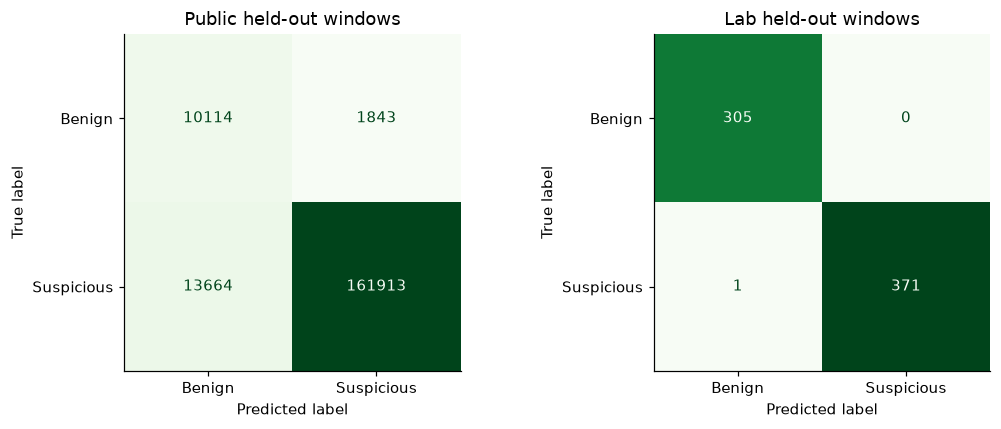

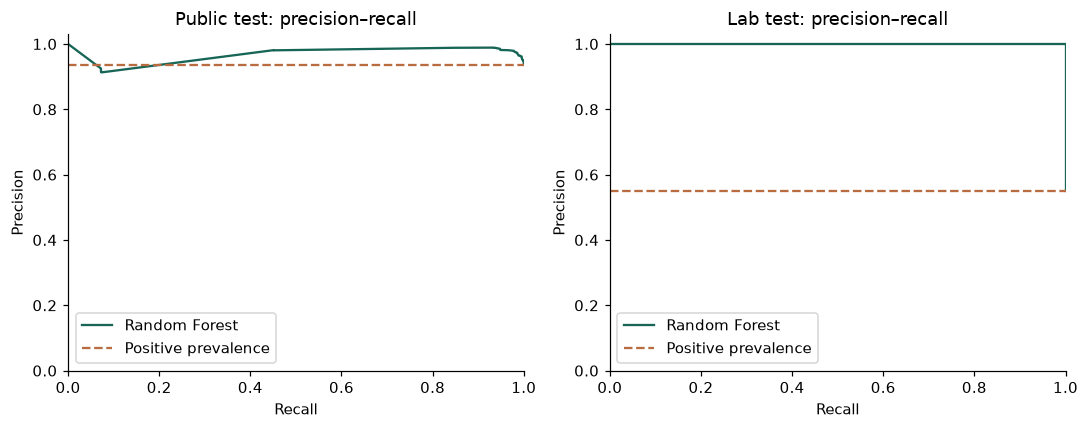

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, domain in zip(axes, ('public', 'lab')):
    y, scores = score_sets[domain]
    ConfusionMatrixDisplay.from_predictions(y, scores >= threshold,
        labels=[0, 1], display_labels=['Benign', 'Suspicious'],
        values_format='d', cmap='Greens', colorbar=False, ax=ax)
    ax.set_title(f'{domain.title()} held-out windows')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'confusion_matrices.png', dpi=180)
fig.savefig(OUTPUT_DIR / 'confusion_matrices.svg')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, domain in zip(axes, ('public', 'lab')):
    y, scores = score_sets[domain]
    precision, recall, _ = precision_recall_curve(y, scores)
    ax.plot(recall, precision, color='#176556', label='Random Forest')
    ax.axhline(float(np.mean(y)), color='#b86c40', linestyle='--', label='Positive prevalence')
    ax.set(xlabel='Recall', ylabel='Precision', xlim=(0, 1), ylim=(0, 1.03),
           title=f'{domain.title()} test: precision–recall')
    ax.legend(loc='lower left')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'precision_recall.png', dpi=180)
plt.show()


## 10. Inspect global feature importance

These impurity-based importances summarize the forest globally. They are not a causal explanation for a particular alert, and correlated features can share importance.


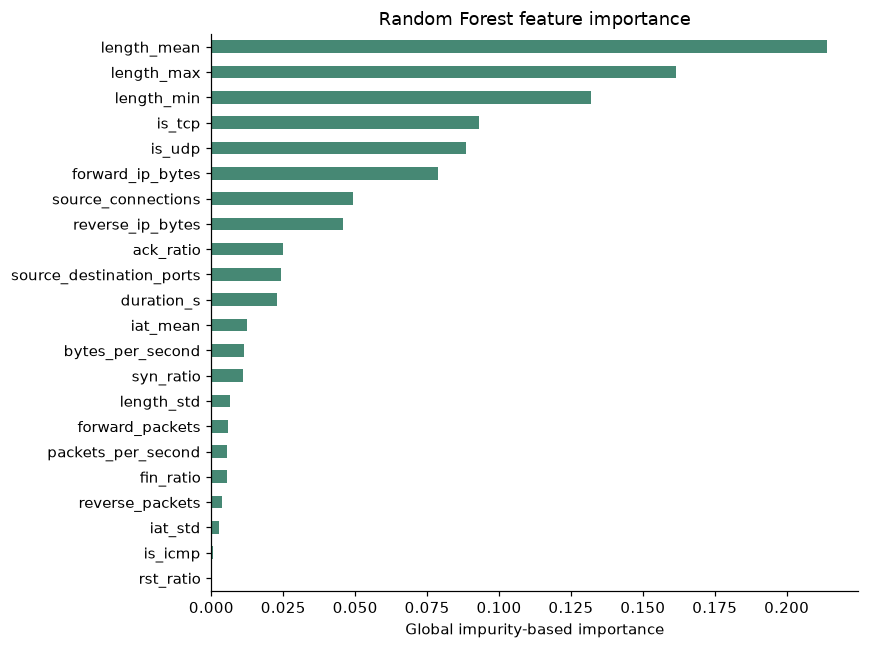

In [10]:
importance = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
importance.plot.barh(ax=ax, color='#468874')
ax.set(xlabel='Global impurity-based importance', ylabel='', title='Random Forest feature importance')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'feature_importance.png', dpi=160)
plt.show()


## 11. Export the experimental model and verify the runtime loader

Save a separate compatible model/metadata pair and metrics in the experiment directory. Loading uses the actual application `Model` class and verifies its hash, schema/order, classes, and scikit-learn version. joblib is pickle-based: load only trusted project artifacts; a hash is not a sandbox.


In [11]:
artifact = OUTPUT_DIR / 'detector.joblib'
joblib.dump(model, artifact, compress=3)
latencies = []
for row in train_x[:100]:
    started = time.perf_counter()
    model.predict_proba(row.reshape(1, -1))
    latencies.append((time.perf_counter() - started) * 1000)
latency = {'median': float(np.median(latencies)), 'p95': float(np.percentile(latencies, 95))}
metadata = {
    'model_version': 'custom-rf-notebook-v1', 'created_at': datetime.now(timezone.utc).isoformat(),
    'schema': SCHEMA, 'features': list(FEATURES), 'threshold': threshold,
    'sha256': sha(artifact), 'sklearn_version': sklearn.__version__, 'python': platform.python_version(),
    'hyperparameters': model.get_params(), 'partitions': {key: sorted(value) for key, value in groups.items()},
    'dataset_lock_sha256': sha(ROOT / 'data/sources.lock.json'),
    'inference_single_window_ms': latency,
    'score_meaning': 'Uncalibrated suspicious-class score, not probability of an attack.',
    'feature_importances': dict(zip(FEATURES, model.feature_importances_.tolist())),
    'preparation_fingerprint': fingerprint,
    'origin': 'Fresh notebook reproduction of previously published partitions; no automatic deployment.',
}
(OUTPUT_DIR / 'metadata.json').write_text(json.dumps(metadata, indent=2) + '\n')
(OUTPUT_DIR / 'model_metrics.json').write_text(json.dumps(
    {'threshold': threshold, 'results': results, 'latency': latency}, indent=2) + '\n')
(OUTPUT_DIR / 'data_quality.json').write_text(json.dumps(
    {'schema': SCHEMA, 'features': list(FEATURES), 'captures': quality_rows}, indent=2) + '\n')
experimental = Model(OUTPUT_DIR)
assert experimental.status == 'ready', experimental.error
probe = [{'values': row.tolist()} for row in train_x[:8]]
assert np.allclose(experimental.scores(probe), model.predict_proba(train_x[:8])[:, 1])
display(pd.DataFrame([{'artifact_loader': experimental.status, 'threshold': threshold,
                       'model_bytes': artifact.stat().st_size,
                       'median_single_window_ms': latency['median'], 'p95_ms': latency['p95']}]))


,artifact_loader,threshold,model_bytes,median_single_window_ms,p95_ms
0,ready,0.95,189718,44.775772,59.923144


## 12. Use this experimental model in offline detection

Analyze the committed synthetic PCAP using the actual engine and experimental model directory. This transmits no packets and starts no services. The fixture exercises rules; it is not a held-out model-accuracy test. A unique database keeps each notebook execution separate.


In [12]:
from ids_lab.engine import replay
from ids_lab.store import connect_readonly, query_events, summary

database = OUTPUT_DIR / f'offline-replay-{SESSION_ID}.sqlite3'
pipeline_stats = replay(ROOT / 'examples/scenarios.pcap', database, model_dir=OUTPUT_DIR)
with connect_readonly(database) as connection:
    events = query_events(connection, limit=500)
    demo_summary = summary(connection)
signatures = sorted({rule for event in events for rule in event['rule_ids']})
assert signatures == [f'CUSTOM-00{index}' for index in range(1, 6)]
display(pd.DataFrame([{'packets': pipeline_stats['packets'], 'alert_windows': demo_summary['events'],
                       'incidents': demo_summary['incidents'], 'custom_signatures': len(signatures),
                       'model_status': demo_summary['state']['sensor']['model_status']}]))
(OUTPUT_DIR / 'offline_summary.json').write_text(json.dumps(demo_summary, indent=2) + '\n')


,packets,alert_windows,incidents,custom_signatures,model_status
0,33,9,1,5,ready


785

## 13. Run software tests and confirm the published files are preserved

The tests check software behavior and the packaged model. They do not replace held-out statistical evaluation. No browser installation or live Docker capture is started automatically here; the project README documents those optional checks.


In [13]:
test_result = {'executed': False}
if RUN_SOFTWARE_TESTS:
    process = subprocess.run([sys.executable, '-m', 'pytest', '-q', '--tb=short'],
        cwd=ROOT, capture_output=True, text=True, timeout=180)
    transcript = process.stdout + process.stderr
    print(transcript)
    (OUTPUT_DIR / 'python_tests.txt').write_text(transcript.rstrip() + '\n')
    assert process.returncode == 0, 'Software tests failed; inspect the transcript.'
    test_result = {'executed': True, 'exit_code': process.returncode}

protected_after = {name: sha(ROOT / name) for name in PROTECTED_FILES}
assert protected_after == PROTECTED_BEFORE, 'A published artifact/report changed unexpectedly.'
display(pd.DataFrame([{'file': name, 'unchanged': protected_after[name] == digest}
                      for name, digest in PROTECTED_BEFORE.items()]))
execution_summary = {
    'completed_at': datetime.now(timezone.utc).isoformat(), 'python': platform.python_version(),
    'sklearn': sklearn.__version__, 'schema': SCHEMA, 'threshold': threshold,
    'training_groups': len(groups['train']), 'validation_groups': len(groups['validation']),
    'test_groups': len(groups['test']), 'experimental_artifact_loader': experimental.status,
    'offline_rules_verified': signatures, 'software_tests': test_result,
    'published_files_unchanged': True, 'protected_sha256': protected_after,
}
(OUTPUT_DIR / 'execution_summary.json').write_text(json.dumps(execution_summary, indent=2) + '\n')
print('Notebook complete. Experimental outputs:', OUTPUT_DIR.relative_to(ROOT))


..............................                                           [100%]
30 passed in 14.70s



,file,unchanged
0,models/detector.joblib,True
1,models/metadata.json,True
2,reports/model_metrics.json,True
3,reports/data_quality.json,True
4,data/sources.lock.json,True


Notebook complete. Experimental outputs: artifacts/notebook-runs/reproduction-v1


## 14. Manual deployment and next experiments

Run All does not promote this model. To deliberately deploy it later, first review results and update the model card/report. Then copy the complete experimental weights/metadata pair (and matching metrics) to the application locations, rebuild, and recreate the Docker stack. Matching feature code and dependency versions are required.

```bash
# Manual commands from repository root; NOT executed by this notebook.
cp artifacts/notebook-runs/reproduction-v1/detector.joblib models/detector.joblib
cp artifacts/notebook-runs/reproduction-v1/metadata.json models/metadata.json
cp artifacts/notebook-runs/reproduction-v1/model_metrics.json reports/model_metrics.json
docker compose build target
docker compose up -d --no-build --force-recreate
```

Use the documented explicit-CA Bake build alternative when required. Recompute reports when parameters/threshold change; rendering a static Markdown report does not update its numeric claims. For a new experiment use a new output directory/version, tune on training/validation data, and reserve a new untouched test set when prior test results have influenced decisions.

The original public benchmark has substantial false positives and correlated/imbalanced windows. Generated lab sessions are simpler. Supported live demonstrations, rule tests, and benchmark performance answer different questions. See `MODEL_CARD.md` for the full limitations and `notebooks/README.md` for launch instructions.
